In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/monitoramento_ti_infra.csv')
df.head()

,timestamp,server_id,metric_type,latency_ms,cpu_usage_pct,memory_usage_gb,status_code
0,2026-08-01 08:00:00,SRV-04,database,54.53,12.99,9.73,200
1,2026-08-01 08:05:00,SRV-03,api_gateway,64.58,60.05,13.60,200
2,2026-08-01 08:10:00,SRV-03,web_server,73.65,91.50,21.17,200
3,2026-08-01 08:15:00,SRV-03,api_gateway,55.97,91.89,20.52,200
4,2026-08-01 08:20:00,SRV-03,web_server,69.74,77.95,11.60,200


In [ ]:
# 2.1 Limpeza e preparação

print(df.info())
print(df.describe())
print(df.isnull().sum())
print(df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   timestamp        500 non-null    object 
 1   server_id        500 non-null    object 
 2   metric_type      500 non-null    object 
 3   latency_ms       500 non-null    float64
 4   cpu_usage_pct    500 non-null    float64
 5   memory_usage_gb  500 non-null    float64
 6   status_code      500 non-null    int64  
dtypes: float64(3), int64(1), object(3)
memory usage: 27.5+ KB
None
       latency_ms  cpu_usage_pct  memory_usage_gb  status_code
count  500.000000     500.000000       500.000000   500.000000
mean    49.751900      49.975900        17.203480   225.594000
std     14.870005      25.151744         8.619023    79.703541
min      0.530000       5.060000         2.020000   200.000000
25%     40.632500      28.267500         9.777500   200.000000
50%     50.810000      50.460000    

In [ ]:
#2.2 Análise Estatística Descritiva
#Utilização do for para correr as colunas.

metricas = ['latency_ms', 'cpu_usage_pct', 'memory_usage_gb']

for coluna in metricas:
  print('Média:', df[coluna].mean())
  print('Mediana', df[coluna].median())
  print('Desvio Padrão:', df[coluna].std())
  print('Mínimo:', df[coluna].min())
  print('Máximo:', df[coluna].max())

df[metricas].describe()



Média: 49.7519
Mediana 50.81
Desvio Padrão: 14.870004756991364
Mínimo: 0.53
Máximo: 90.65
Média: 49.9759
Mediana 50.459999999999994
Desvio Padrão: 25.15174352195865
Mínimo: 5.06
Máximo: 94.88
Média: 17.20348
Mediana 17.06
Desvio Padrão: 8.61902308893619
Mínimo: 2.02
Máximo: 31.78


,latency_ms,cpu_usage_pct,memory_usage_gb
count,500.000000,500.000000,500.000000
mean,49.751900,49.975900,17.203480
std,14.870005,25.151744,8.619023
min,0.530000,5.060000,2.020000
25%,40.632500,28.267500,9.777500
50%,50.810000,50.460000,17.060000
75%,59.527500,71.900000,24.817500
max,90.650000,94.880000,31.780000


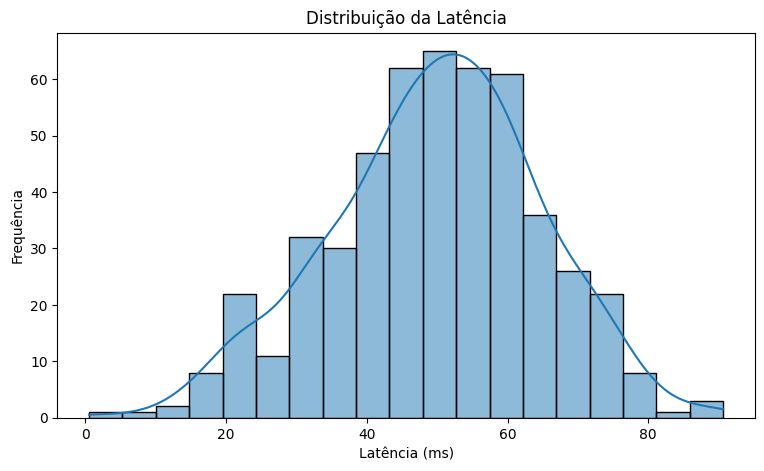

In [ ]:
#2.3 Visualização Latência

plt.figure(figsize=(9,5))
sns.histplot(df['latency_ms'], kde=True)
plt.title('Distribuição da Latência')
plt.xlabel('Latência (ms)')
plt.ylabel('Frequência')
plt.show()

/tmp/ipykernel_2753/2406524786.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='metric_type', y='cpu_usage_pct', palette='Set2')


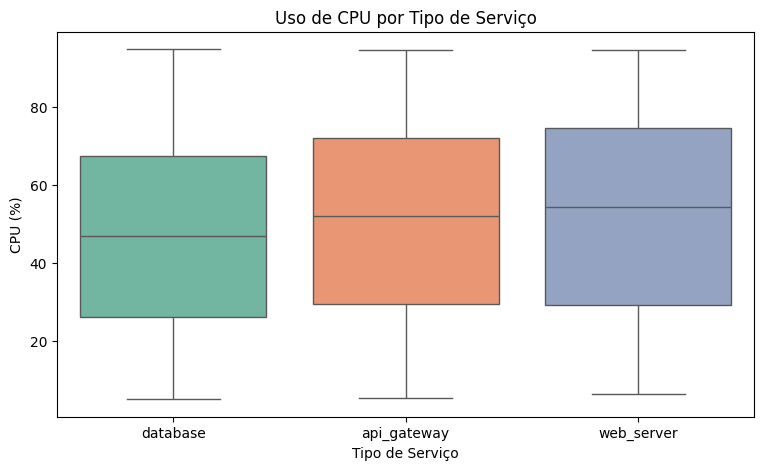

In [ ]:
#2.3 Visualização Boxplot CPU

plt.figure(figsize=(9,5))
sns.boxplot(data=df, x='metric_type', y='cpu_usage_pct', palette='Set2')
plt.title('Uso de CPU por Tipo de Serviço')
plt.xlabel('Tipo de Serviço')
plt.ylabel('CPU (%)')
plt.show()

/tmp/ipykernel_2753/3478938757.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='metric_type', y='memory_usage_gb', palette='Set2')


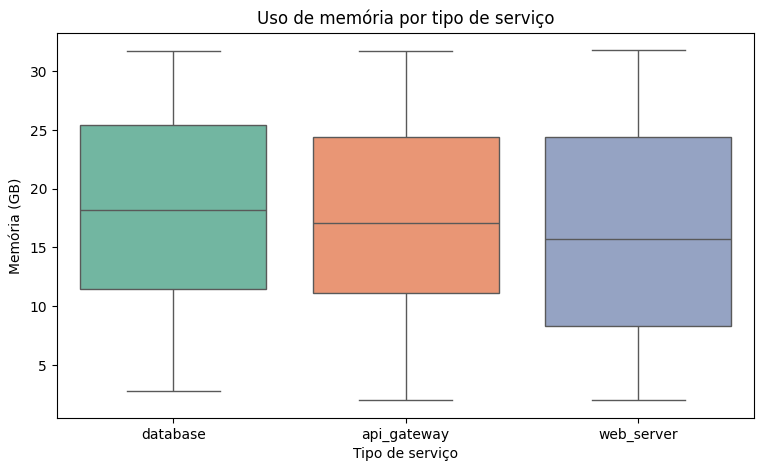

In [ ]:
#2.3 Visualização Boxplot Memória

plt.figure(figsize=(9,5))
sns.boxplot(data=df, x='metric_type', y='memory_usage_gb', palette='Set2')
plt.title('Uso de memória por tipo de serviço')
plt.xlabel('Tipo de serviço')
plt.ylabel('Memória (GB)')
plt.show()

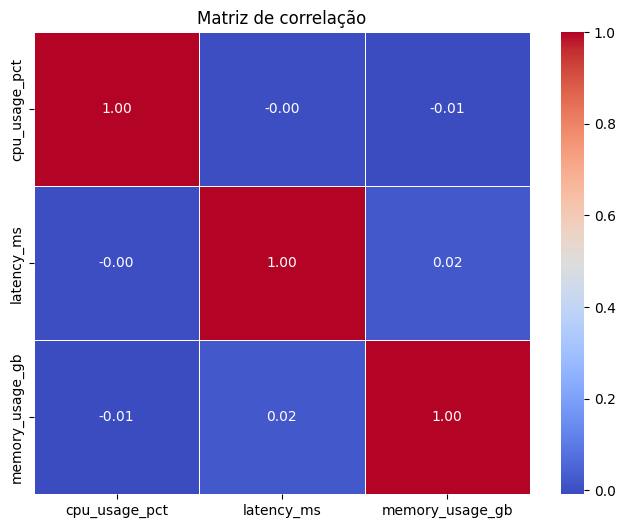

In [ ]:
#2.4 Correlação entre CPU e latência usando heatmap.

corr = df[['cpu_usage_pct', 'latency_ms', 'memory_usage_gb']].corr()

plt.figure(figsize= (8,6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f',linewidths=0.5)
plt.title('Matriz de correlação')
plt.show()

A análise dos 500 registros mostrou que a latência dos servidores ficam em média perto dos 50 ms, e o histograma mostrou uma distribuição bem próxima do formato normal (em sino), sem muita assimetria. Comparando os tipos de serviço, o uso da CPU foi subindo aos poucos, o database ficou com mediana de 45%, o api_gateway com 50% e o web_server com 55%, sendo o mais alto dos três. Mesmo assim, nenhum dos três grupos apresentou outliers nos boxplots de CPU e memória.

O ponto mais importante da análise foi o heatmap de correlação. Os valores entre CPU e latência (-0,00) e entre memória e latência (0,02) ficaram praticamente zero, o que mostra que não existe relação notável entre o uso de CPU e a latência dos servidores. Ou seja, mesmo os servidores com mais uso de CPU não estão necessariamente respondendo mais devagar.

Do ponto de vista de negócio, isso é uma boa notícia, não há motivo, nesses dados, para justificar a compra de mais servidores ou upgrade de CPU agora. O Web_server chamou atenção por ter o uso de CPU mais alto entre os três serviços, o que pode virar um problema se a demanda aumentar no futuro. Como a latência não é explicada pela CPU ou pela memória, a recomendação é continuar de olho no web server e investigar outras possíveis causas de lentidão, como rede, banco de dados ou a própria aplicação, antes de investir em mais hardware.